In [2]:
import pandas as pd
import boto3
from io import BytesIO


In [3]:
# Connect to LocalStack S3 endpoint
import boto3

s3 = boto3.client(
    "s3",
    region_name="us-east-1",
    endpoint_url="http://localhost:4566",  # LocalStack endpoint
    aws_access_key_id="test",
    aws_secret_access_key="test"
)

print("✅ Connected to LocalStack S3 successfully!")


✅ Connected to LocalStack S3 successfully!


In [4]:
from io import BytesIO
import pandas as pd

bucket_name = "zazi-data-bucket"
file_key = "etl-output/zazi_etl_output.parquet"

# Fetch the Parquet file from LocalStack S3
obj = s3.get_object(Bucket=bucket_name, Key=file_key)
data = obj["Body"].read()

# Read the Parquet file into a DataFrame
df = pd.read_parquet(BytesIO(data))

print("✅ Data successfully loaded from LocalStack S3!")
df.head()


✅ Data successfully loaded from LocalStack S3!


,customer_id,name,city,purchase_value,purchase_value_with_vat,segment
0,101,Zazi,Cape Town,250,287.5,Low
1,102,Amahle,Joburg,400,460.0,High
2,103,Kwena,Durban,320,368.0,High
3,104,Nathi,Pretoria,180,207.0,Low


In [5]:
import matplotlib.pyplot as plt

# Aggregate and plot total spend per city
city_spend = df.groupby("city")["purchase_value_with_vat"].sum().sort_values(ascending=False)

city_spend.plot(
    kind="bar",
    title="💰 Total Purchase Value (with VAT) per City",
    ylabel="Total Value (R)",
    xlabel="City",
    figsize=(7, 4),
    color="teal",
    rot=15
)

plt.show()


ModuleNotFoundError: No module named 'matplotlib'

In [6]:
!pip install matplotlib --quiet


/Users/bongilegobile/Desktop/zazi-data-lab/venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128176 (\N{MONEY BAG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


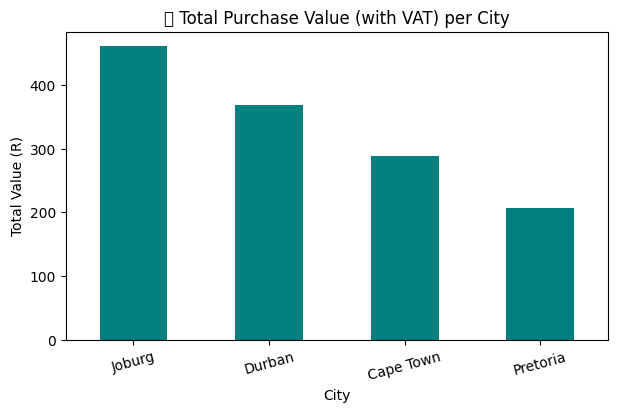

In [7]:
import matplotlib.pyplot as plt

# Aggregate and plot total spend per city
city_spend = df.groupby("city")["purchase_value_with_vat"].sum().sort_values(ascending=False)

city_spend.plot(
    kind="bar",
    title="💰 Total Purchase Value (with VAT) per City",
    ylabel="Total Value (R)",
    xlabel="City",
    figsize=(7, 4),
    color="teal",
    rot=15
)

plt.show()
